# QFF 2026 Phase 2 - PS-S3: Trotter error vs noise on the ring (Processors A, B and D)

**Team:** Entangled Minds  |  **Problem statement:** PS-S3 (same team and PS as Phase 1)

Run top to bottom with no edits. Uses the organizers' `qff_sim.py` (unchanged) and the official settings; `s3_pipeline.py` only orchestrates the kit's functions.

In [1]:
import platform
import numpy as np
import pandas as pd
import qiskit, qiskit_aer
from IPython.display import Image, display
import qff_sim as q
import s3_pipeline as s3

print('python', platform.python_version(), '| qiskit', qiskit.__version__, '| aer', qiskit_aer.__version__)
# official settings (fixed by the organizers, NOT changed here)
print('opt_level', q.OPT_LEVEL, '| seed', q.SEED, '| shots', q.SHOTS,
      '| p1/p2/readout', q.P1_DEPOL, q.P2_DEPOL, q.P_READOUT, '| basis', q.BASIS_GATES)

RECOMPUTE = True   # False = reload the saved step scan from results/tables (only after a full run has saved it)

python 3.12.10 | qiskit 1.4.6 | aer 0.18.0
opt_level 1 | seed 42 | shots 4096 | p1/p2/readout 0.001 0.005 0.01 | basis ['rz', 'sx', 'x', 'cx']


## 1. Processors A, B and D
A and B are the official maps; D is our design (`processors/processor_D.json`, frozen at the final commit).

A | 5 qubits | 4 couplings | ['rz', 'sx', 'x', 'cx']
B | 9 qubits | 12 couplings | ['rz', 'sx', 'x', 'cx']
D | 6 qubits | 6 couplings | ['rz', 'sx', 'x', 'rzz']


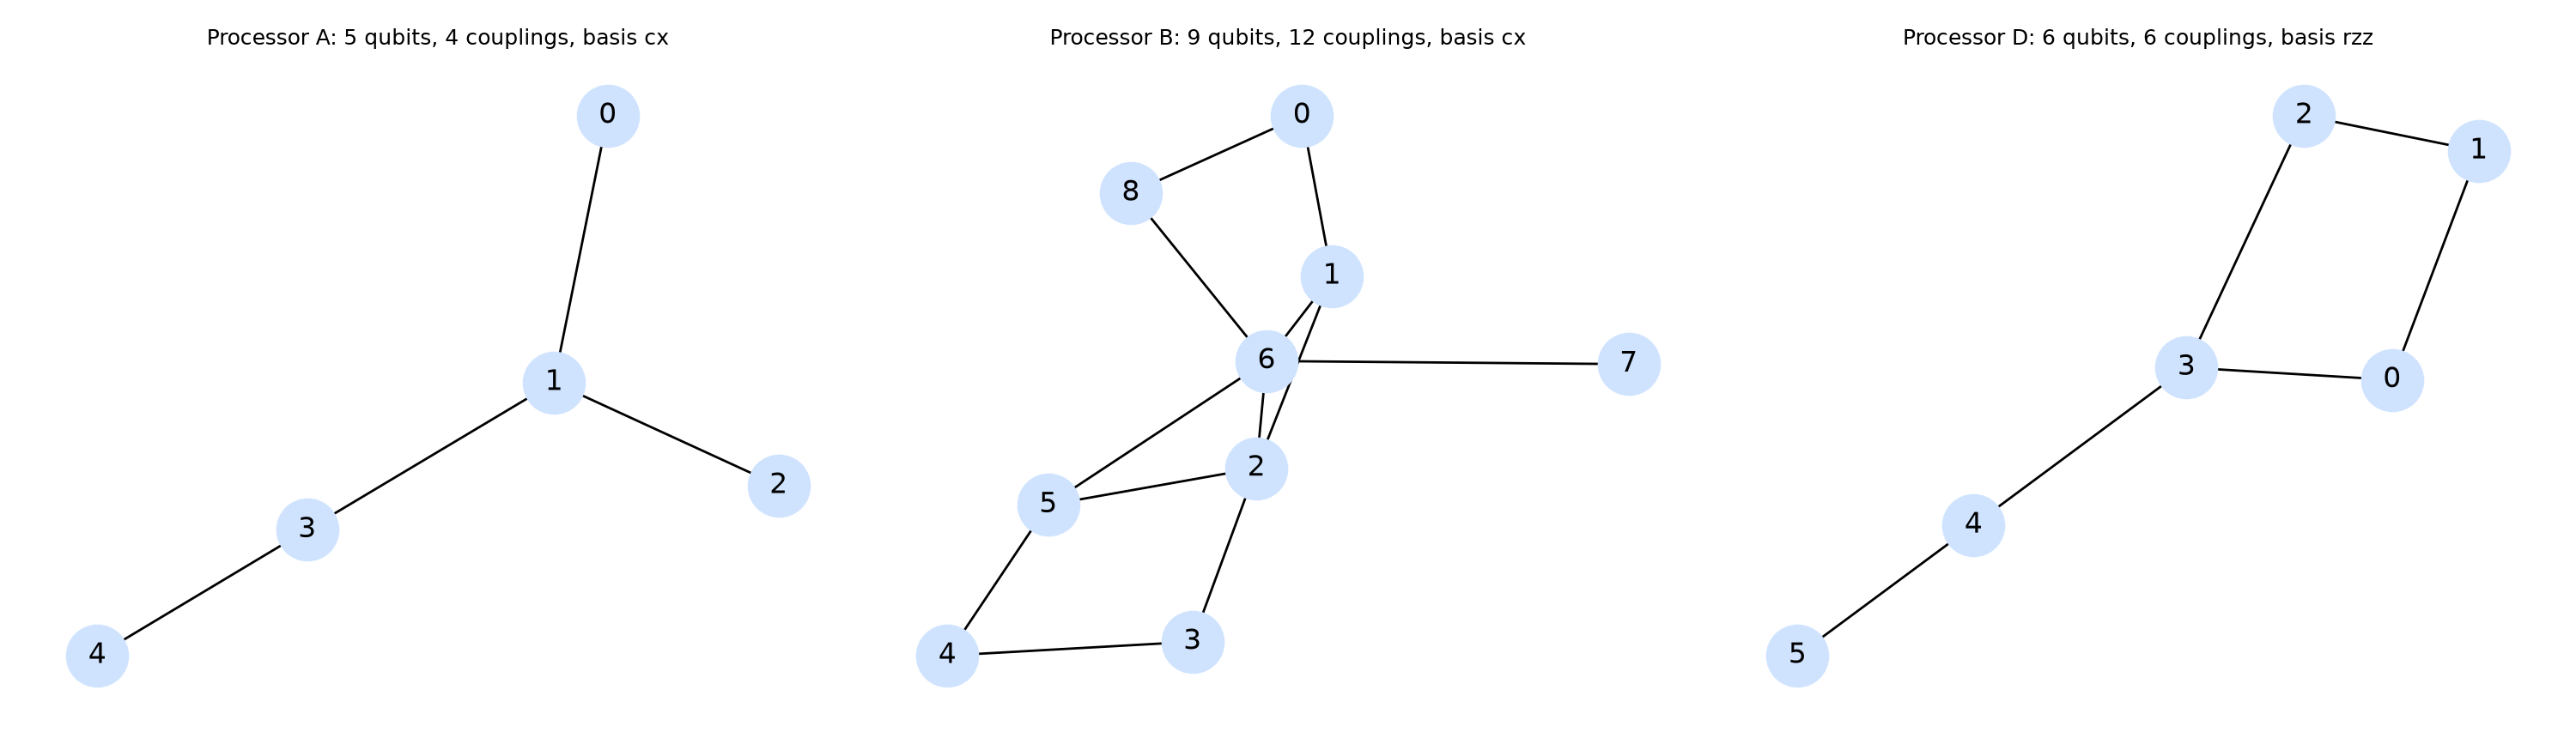

In [2]:
procs = s3.load_processors()        # raises with the rule violations if processor_D.json is invalid
for k, P in procs.items():
    print(k, '|', P['num_qubits'], 'qubits |', len(P['edges']), 'couplings |', P.get('basis_gates', q.BASIS_GATES))
s3.plot_processor_graphs(procs)
display(Image('results/figures/processor_graphs.png'))

## 2. Exact reference: ring, Neel 1010, T = 2 (locked data `data/s3/tfim_ring_N4_g1.00.json`)

In [3]:
target, ms_exact = s3.exact_reference()
print('exact staggered magnetization M_s(T) =', round(ms_exact, 5))

exact staggered magnetization M_s(T) = 0.65244


## 3. Step scan on A, B and D (headline) and n*
For every n: noisy density-matrix fidelity F(n) (required metric), noise-free Trotter fidelity, M_s from 4096 noisy shots, logical vs routing two-qubit gates. Processor D is also scanned at 0.5x and 2x noise.

In [4]:
scan, res = s3.run_scan(procs, target, ms_exact, recompute=RECOMPUTE)
summary = s3.summarize(scan)
summary

[A] n= 1  2q= 11 (logical 8, routing 3) swaps=1  F(1x)=0.1101   [0s]


[A] n= 2  2q= 25 (logical 16, routing 9) swaps=3  F(1x)=0.2619   [0s]


[A] n= 3  2q= 39 (logical 24, routing 15) swaps=5  F(1x)=0.0685   [0s]


[A] n= 4  2q= 53 (logical 32, routing 21) swaps=7  F(1x)=0.4050   [1s]


[A] n= 5  2q= 67 (logical 40, routing 27) swaps=9  F(1x)=0.5464   [1s]

...

[D] n=10  2q= 40 (logical 40, routing 0) swaps=0  F(1x)=0.7323   [8s]


[D] n=12  2q= 48 (logical 48, routing 0) swaps=0  F(1x)=0.7017   [8s]


[D] n=14  2q= 56 (logical 56, routing 0) swaps=0  F(1x)=0.6690   [8s]


[D] n=16  2q= 64 (logical 64, routing 0) swaps=0  F(1x)=0.6363   [9s]


,processor,noise_scale,n_star,fidelity_at_n_star
0,A,1.0,6,0.577419
1,B,1.0,7,0.662816
2,D,0.5,8,0.841453
3,D,1.0,8,0.752817
4,D,2.0,7,0.620712


## 4. Figures: crossover, noise sweep, gate split, M_s

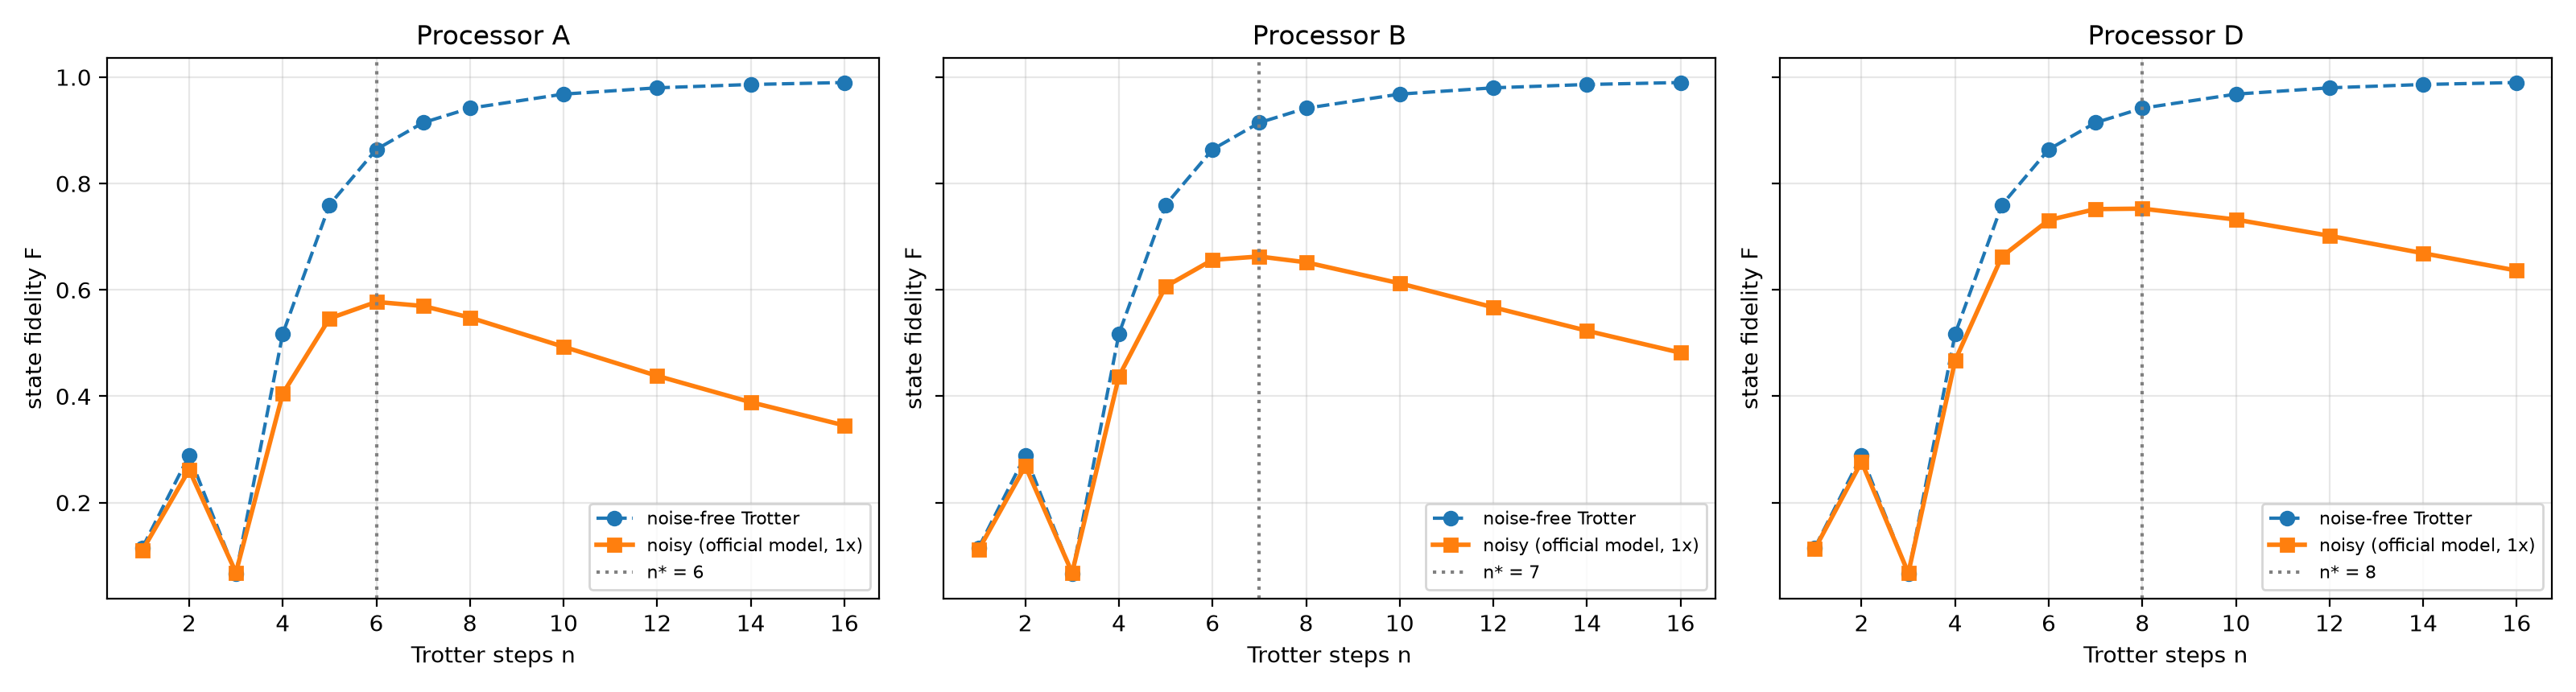

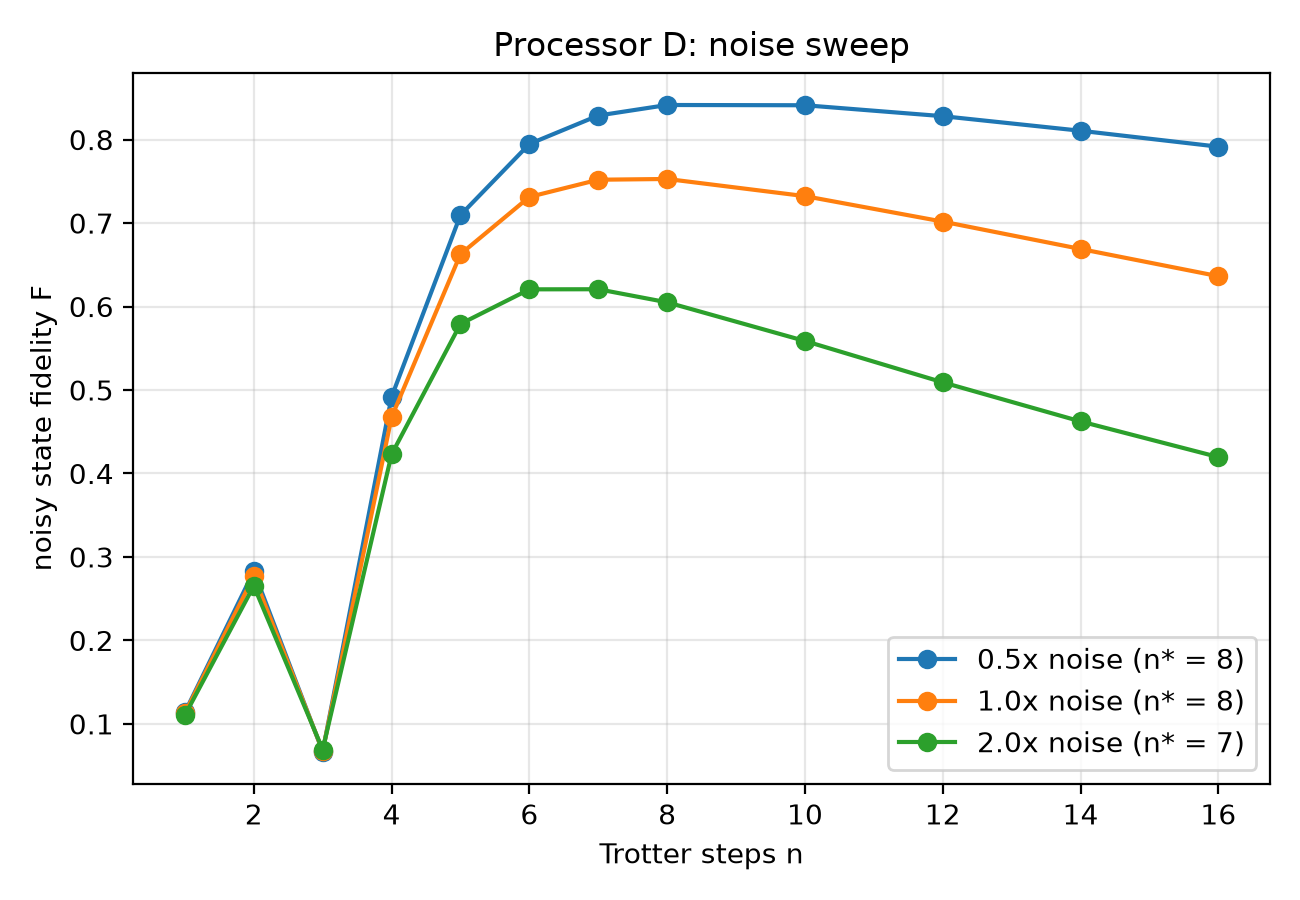

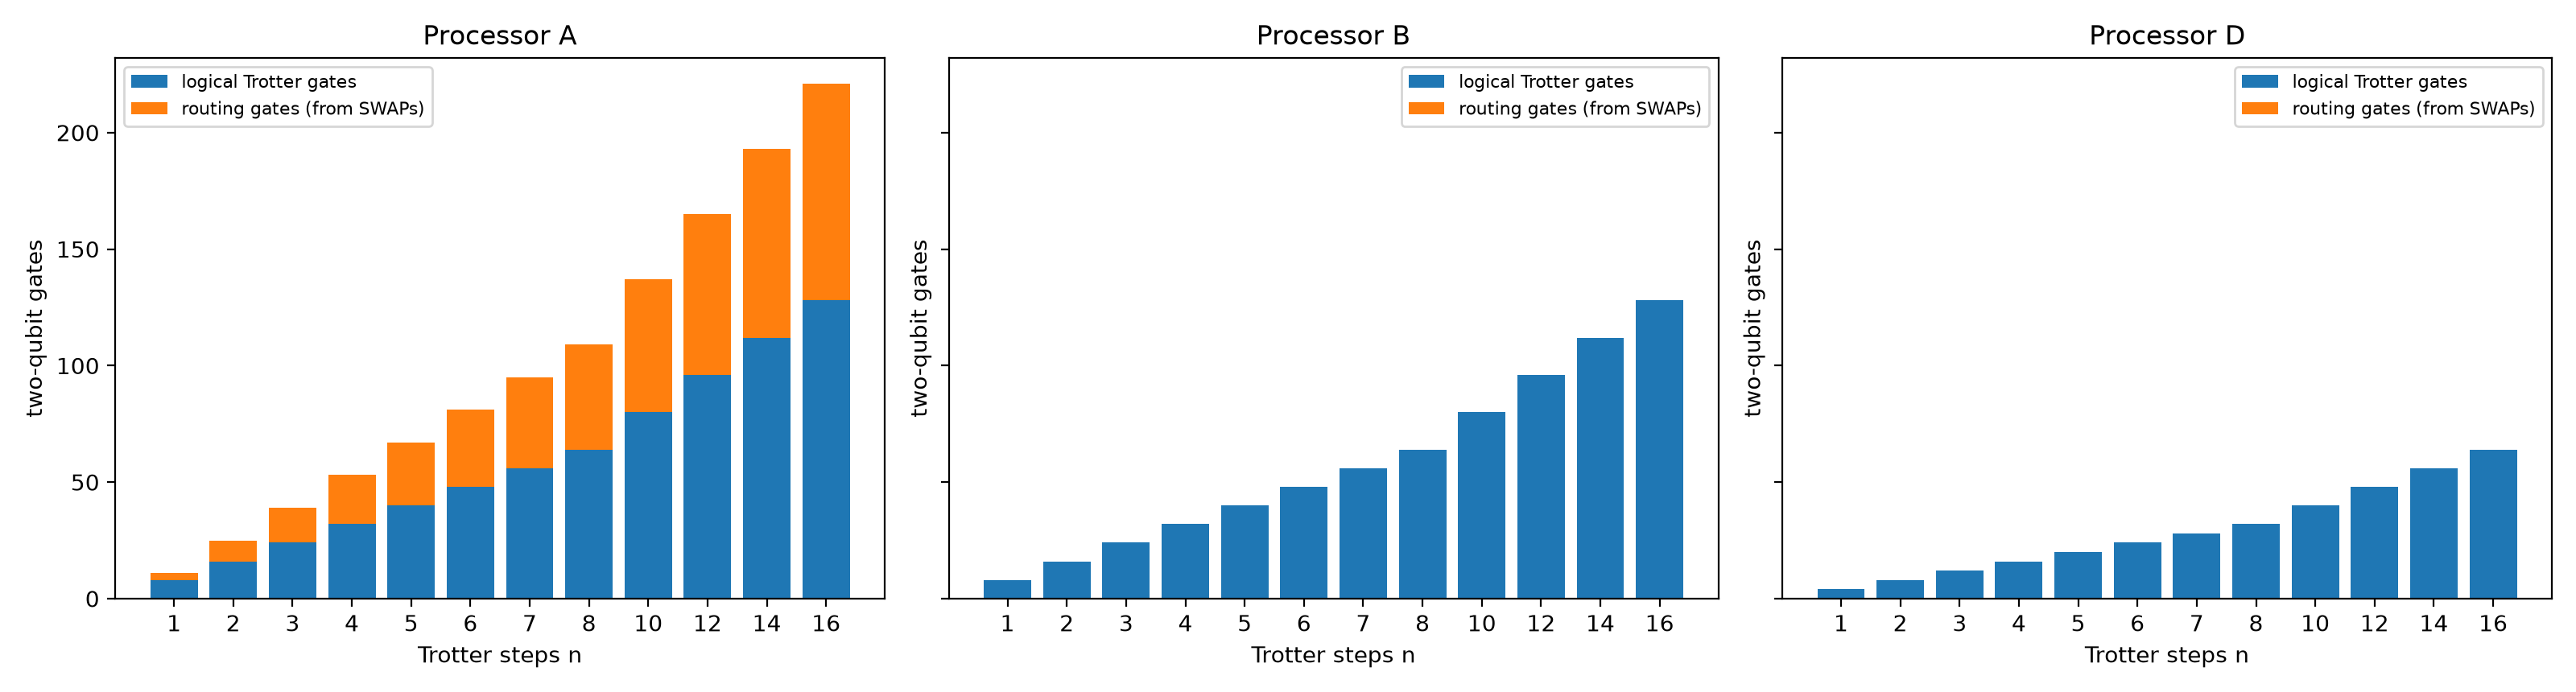

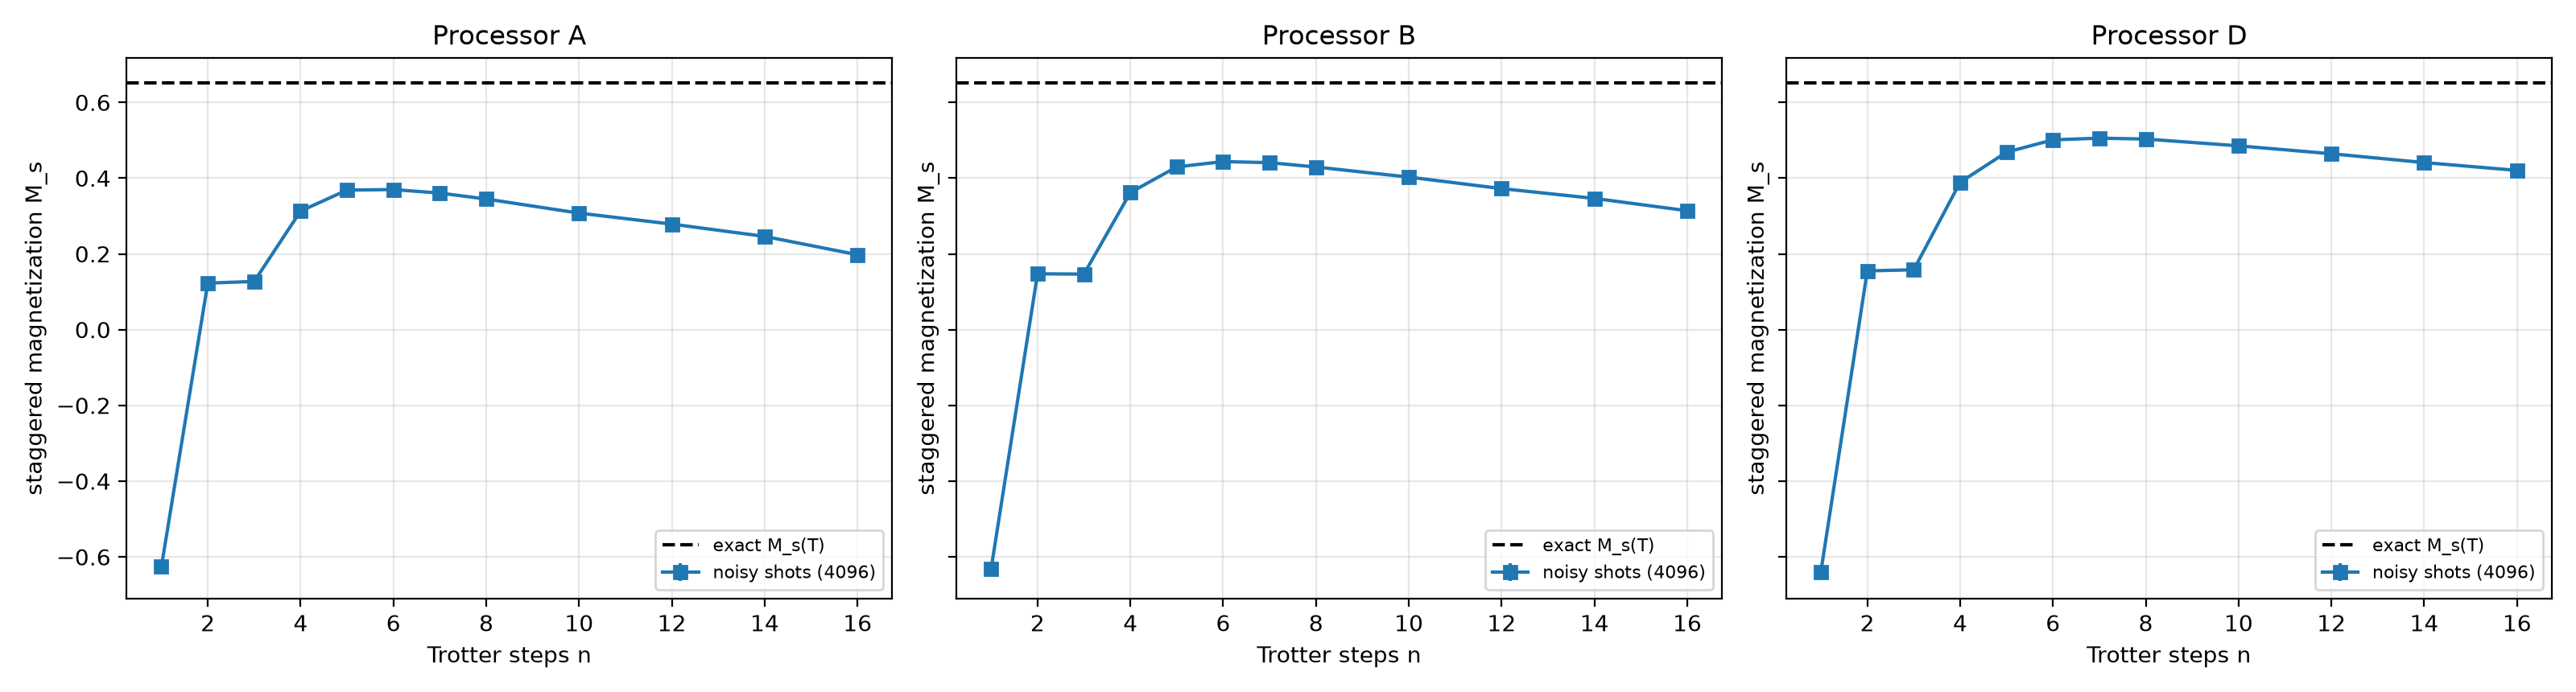

In [5]:
s3.make_figures(scan, summary)
for f in ['s3_fidelity_vs_steps', 's3_noise_sweep_D', 's3_gate_split', 's3_ms_vs_steps']:
    display(Image(f'results/figures/{f}.png'))

## Supplementary: time-resolved error decomposition
This analysis samples the same locked Hamiltonian over 9 times in [0, 2]. It is additional evidence; the official PS-S3 endpoint scan and settings above remain unchanged. The supplementary density-matrix M_s values are deterministic and exclude readout noise.

,processor,noise_scale,minimum RMSE
0,A,1.0,0.161801
1,B,1.0,0.127546
2,D,0.0,0.004874
3,D,0.5,0.060490
4,D,1.0,0.094817
5,D,2.0,0.144919


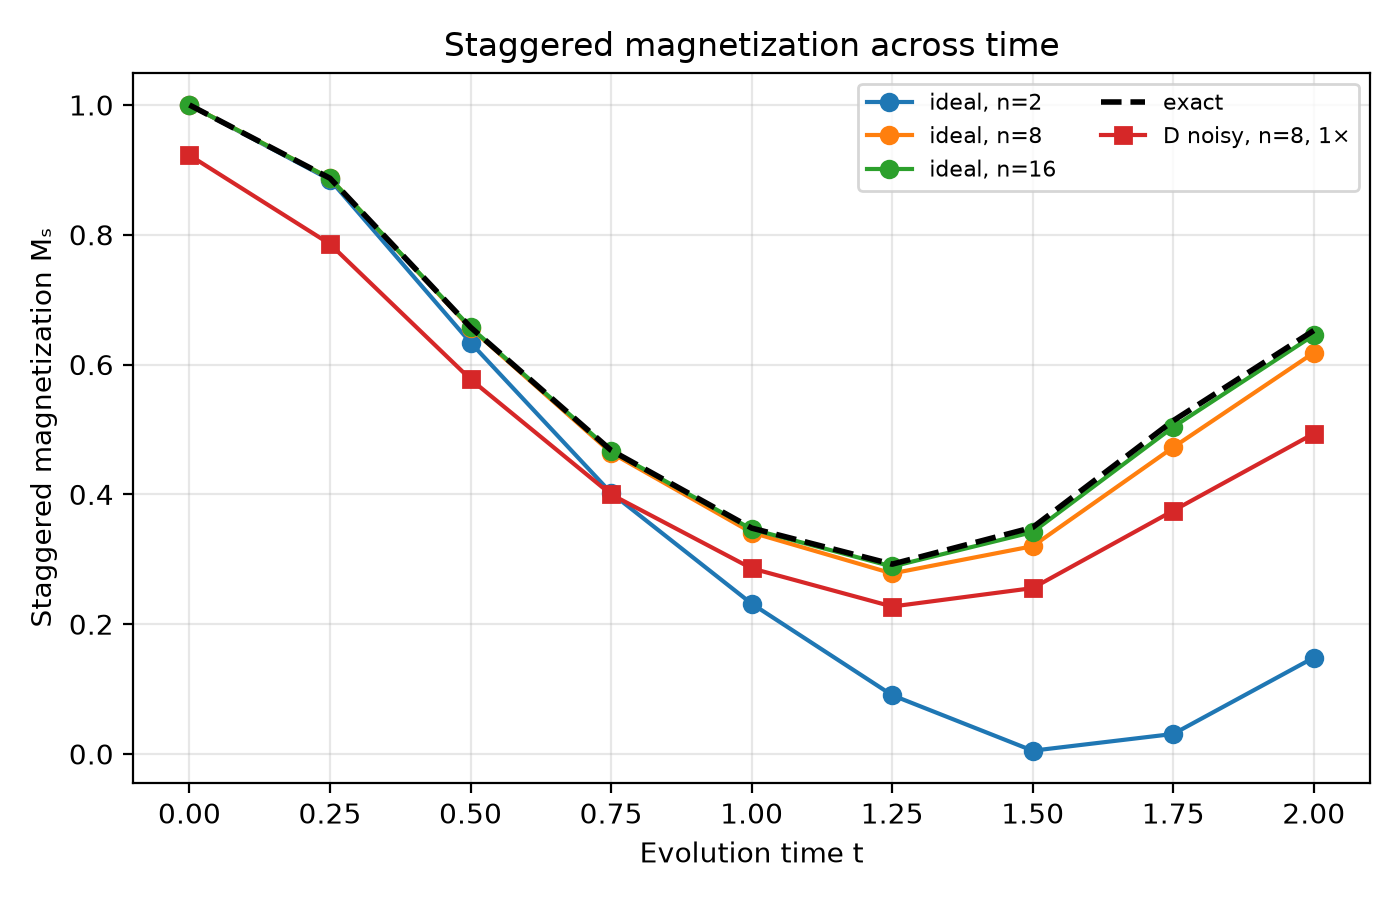

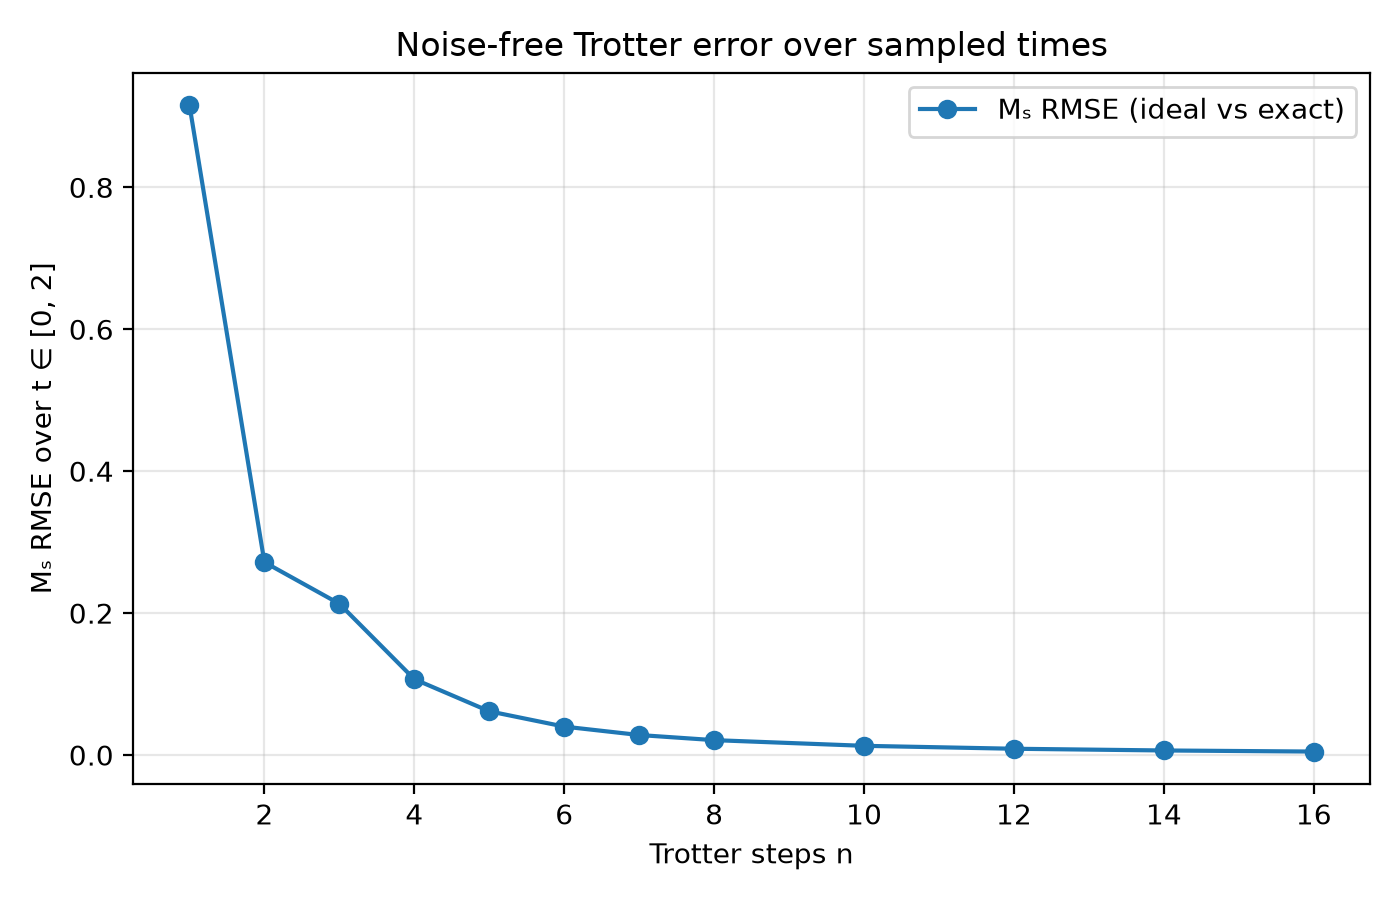

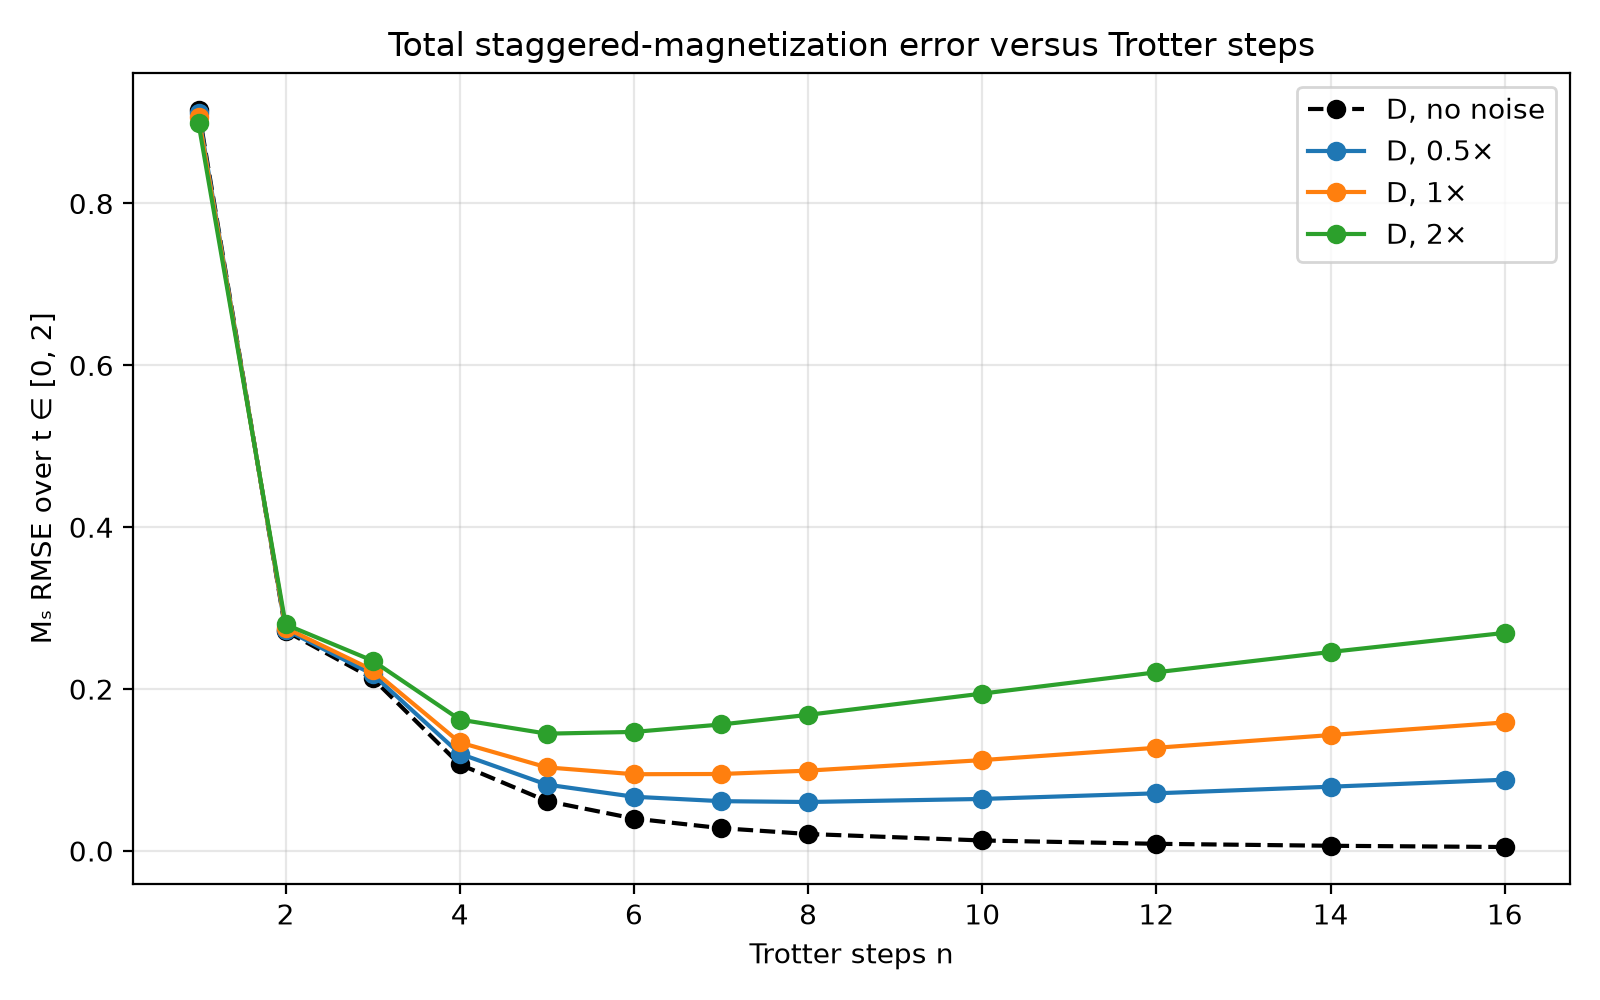

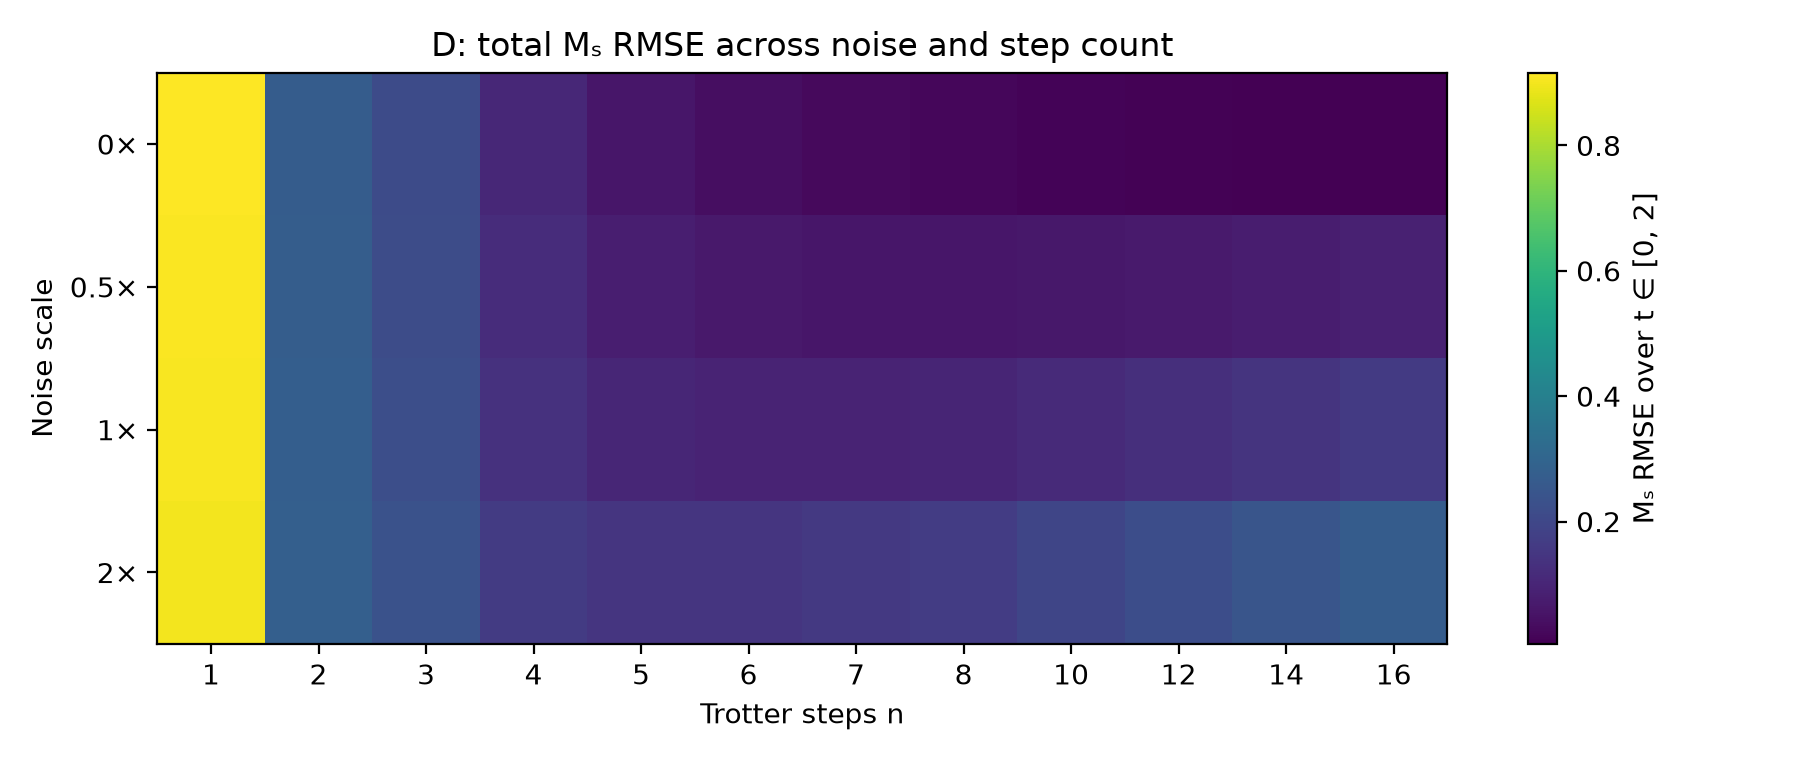

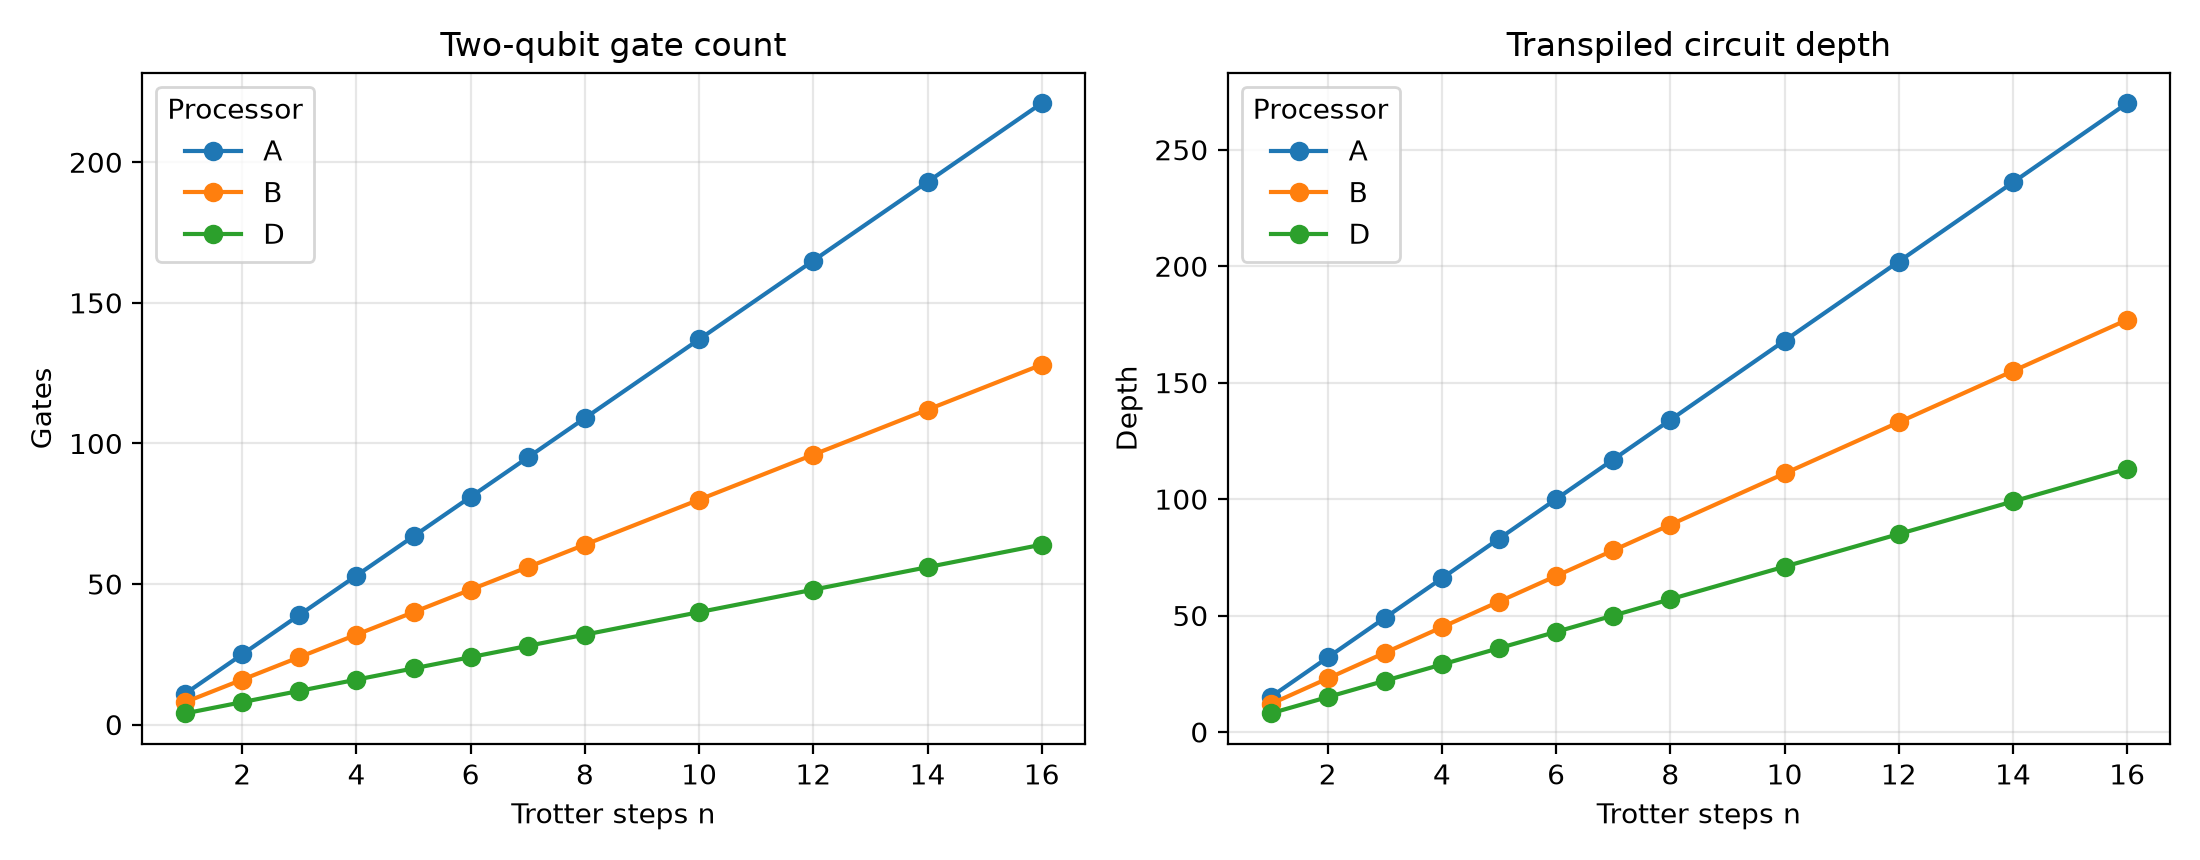

In [6]:
error_data, error_summary = s3.run_error_analysis(procs, res)
s3.plot_error_analysis(error_data, error_summary)
display(error_summary.groupby(['processor', 'noise_scale'])['total_ms_rmse'].min().rename('minimum RMSE').reset_index())
for f in ['s3_observable_dynamics', 's3_trotter_error_vs_steps', 's3_total_error_vs_steps_noise', 's3_error_heatmap', 's3_circuit_cost_vs_steps']:
    display(Image(f'results/figures/{f}.png'))

## 5. Objective 1: Bell state on Processor D (directly connected pair and farthest pair)

In [7]:
bell = s3.run_bell(procs['D'])
bell

,pair,pair_distance,condition,two_qubit_gates,XX,XX_se,YY,YY_se,ZZ,ZZ_se,fidelity,fidelity_se
0,"(0, 1)",1,ideal,1,1.000000,0.000000,-1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
1,"(0, 1)",1,noisy,1,0.946289,0.005052,-0.946777,0.005030,0.946289,0.005052,0.959839,0.002184
2,"(1, 5)",4,ideal,10,1.000000,0.000000,-1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
3,"(1, 5)",4,noisy,10,0.903809,0.006687,-0.886719,0.007224,0.924805,0.005944,0.928833,0.002875


## 6. Bonus: readout-error correction of M_s at n* on D

In [8]:
n_star = int(summary[(summary.processor == 'D') & np.isclose(summary.noise_scale, 1.0)].n_star.iloc[0])
mit, factor = s3.readout_mitigation(procs['D'], n_star)
print('n* on D (1x) =', n_star, '| calibration factor (1 - 2p) =', round(factor, 4), '| exact M_s =', round(ms_exact, 4))
mit

n* on D (1x) = 8 | calibration factor (1 - 2p) = 0.9834 | exact M_s = 0.6524


,method,ms_raw,ms_mitigated,extra_shots
0,readout correction (symmetric-flip calibration),0.503174,0.511668,4096


## 7. Resource table (A, B, D) and environment

In [9]:
print(res.to_string(index=False))
s3.save_environment()

ps  circuit_label processor  executable  logical_qubits  physical_qubits  logical_2q  two_q  depth  two_q_depth  swaps  routing_overhead_2q
S3  ring_N4_T2_n1         A        True               4                5           8     11     15            7      1                    3
S3  ring_N4_T2_n2         A        True               4                5          16     25     32           17      3                    9
S3  ring_N4_T2_n3         A        True               4                5          24     39     49           27      5                   15
S3  ring_N4_T2_n4         A        True               4                5          32     53     66           37      7                   21
S3  ring_N4_T2_n5         A        True               4                5          40     67     83           47      9                   27
S3  ring_N4_T2_n6         A        True               4                5          48     81    100           57     11                   33
S3  ring_N4_T2_n7   

## 8. Interpretation
_See `report.md`. Every number there must match the tables above._